# 05 · Deployment, Predictions & Summary
**Chest X-Ray Classification with ResNet50 Transfer Learning (TensorFlow / Keras)**  
*Tasks 4-5* · MSc Data Science group project

**In this notebook**
- Save and reload the model with a class-index mapping
- Reusable predict_xray() function with optional TTA
- Predictions on random test images and a prediction grid
- Final results, design decisions, challenges and reflection

> **How to use these notebooks.** The outputs below come from one complete run on a Kaggle Tesla T4 GPU. Each part builds on objects created earlier (data generators, the trained model, predictions), so the part notebooks are for reading and review. To reproduce the results, run [`00_full_pipeline_run_all.ipynb`](00_full_pipeline_run_all.ipynb) top to bottom.

[← Evaluation & Test-Time Augmentation](04_evaluation_and_tta.ipynb)

---

## Task 4 — Deployment and Predictions on Test Set

This section saves the trained model, defines a reusable prediction function that accepts any new X-ray image, and demonstrates it on random test images.

### 4.1 Save Model & Class Mapping

The model is saved in HDF5 format along with a JSON file mapping class indices to class labels, so the prediction function can be used independently of the training environment.

In [ ]:
# ── Save model + class mapping ──────────────────────────────
best_model.save('chest_xray_resnet50_advanced.h5')

class_indices = train_generator.class_indices
with open('class_indices.json', 'w') as f:
    json.dump(class_indices, f)

print("✅ Model saved  →  chest_xray_resnet50_advanced.h5")
print("✅ Class map    →  class_indices.json")
print(f"   Mapping: {class_indices}")


✅ Model saved  →  chest_xray_resnet50_advanced.h5
✅ Class map    →  class_indices.json
   Mapping: {'COVID19': 0, 'NORMAL': 1, 'PNEUMONIA': 2, 'TURBERCULOSIS': 3}


### 4.2 Reload & Verify Model

In [ ]:
# ── Reload & verify ─────────────────────────────────────────
from tensorflow.keras.models import load_model

loaded_model = load_model('chest_xray_resnet50_advanced.h5')
print("✅ Model reloaded successfully")
print(f"   Input  shape: {loaded_model.input_shape}")
print(f"   Output shape: {loaded_model.output_shape}")


✅ Model reloaded successfully
   Input  shape: (None, 224, 224, 3)
   Output shape: (None, 4)


### 4.3 Single-Image Prediction Function

The `predict_xray()` function accepts any `.jpg` or `.png` chest X-ray image path, applies CLAHE preprocessing, optionally runs TTA (10 passes), and returns the predicted class and confidence score.

In [ ]:
# ── Single-image prediction function (with TTA option) ──────
def predict_xray(img_path, model, tta=True, tta_n=10):
    """
    Predict the class of a chest X-ray with optional TTA.

    Args:
        img_path : path to .jpg / .png file
        model    : loaded Keras model
        tta      : use Test-Time Augmentation (default True)
        tta_n    : number of TTA passes (default 10)

    Returns:
        (predicted_class_label, confidence_percent)

    Note: horizontal_flip is intentionally excluded from TTA augmentation.
          Chest X-rays must not be flipped — the left-side heart position
          is a key diagnostic indicator.
    """
    with open('class_indices.json') as f:
        ci = json.load(f)
    idx_to_cls = {v: k for k, v in ci.items()}

    base_img = Image.open(img_path).convert('RGB')
    base_arr = np.array(base_img.resize((224, 224)), dtype=np.uint8)

    def _forward(arr):
        x = clahe_preprocess(arr)
        x = np.expand_dims(x, axis=0)
        return model.predict(x, verbose=0)[0]

    if tta:
        aug = ImageDataGenerator(
            rotation_range=8,
            width_shift_range=0.05,
            height_shift_range=0.05,
            zoom_range=0.05,
            horizontal_flip=False    # ← never flip X-rays
        )
        preds = _forward(base_arr)
        gen   = aug.flow(np.expand_dims(base_arr, 0), batch_size=1)
        for _ in range(tta_n - 1):
            aug_img = next(gen)[0].astype(np.uint8)
            preds  += _forward(aug_img)
        preds /= tta_n
    else:
        preds = _forward(base_arr)

    pred_idx   = np.argmax(preds)
    pred_class = idx_to_cls[pred_idx]
    confidence = preds[pred_idx] * 100

    print(f"🔬 Image       : {img_path}")
    print(f"   Predicted   : {pred_class}  (TTA={tta})")
    print(f"   Confidence  : {confidence:.2f}%")
    print("\n📊 All probabilities:")
    for idx, prob in enumerate(preds):
        marker = " ← predicted" if idx == pred_idx else ""
        print(f"   {idx_to_cls[idx]:15s}: {prob*100:.2f}%{marker}")

    plt.figure(figsize=(5, 5))
    plt.imshow(base_img, cmap='gray')
    col = 'green' if confidence > 80 else 'orange'
    plt.title(f"Pred: {pred_class}\nConf: {confidence:.2f}%",
              fontsize=13, fontweight='bold', color=col)
    plt.axis('off'); plt.tight_layout(); plt.show()
    return pred_class, confidence

print("✅ predict_xray() function defined  (TTA ×10, no horizontal flip)")

✅ predict_xray() function defined  (TTA ×10, no horizontal flip)


### 4.4 Predictions on Random Test Images

One random image per class is selected from the test set and passed through the prediction function.

🔬 Running predictions on random test images …

📌 Actual Class: COVID19
🔬 Image       : /kaggle/input/datasets/jtiptj/chest-xray-pneumoniacovid19tuberculosis/test/COVID19/COVID19(549).jpg
   Predicted   : COVID19  (TTA=True)
   Confidence  : 89.61%

📊 All probabilities:
   COVID19        : 89.61% ← predicted
   NORMAL         : 4.56%
   PNEUMONIA      : 3.20%
   TURBERCULOSIS  : 2.64%


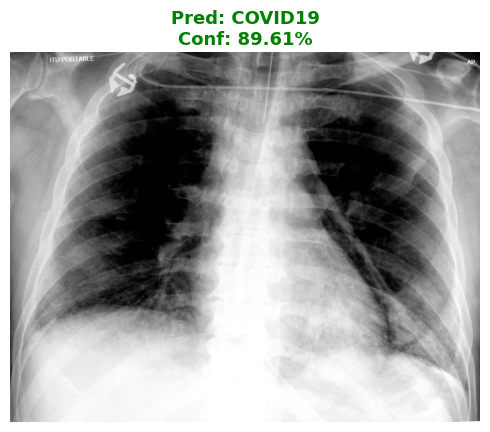


📌 Actual Class: NORMAL
🔬 Image       : /kaggle/input/datasets/jtiptj/chest-xray-pneumoniacovid19tuberculosis/test/NORMAL/NORMAL2-IM-0041-0001.jpeg
   Predicted   : PNEUMONIA  (TTA=True)
   Confidence  : 60.79%

📊 All probabilities:
   COVID19        : 8.31%
   NORMAL         : 17.90%
   PNEUMONIA      : 60.79% ← predicted
   TURBERCULOSIS  : 13.00%


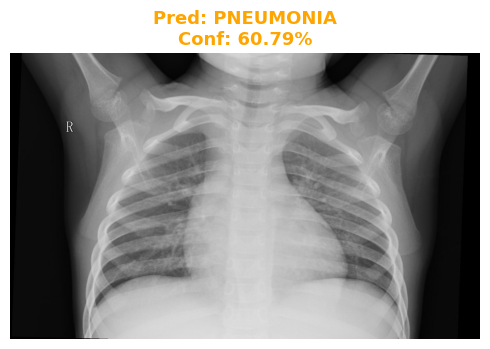


📌 Actual Class: PNEUMONIA
🔬 Image       : /kaggle/input/datasets/jtiptj/chest-xray-pneumoniacovid19tuberculosis/test/PNEUMONIA/person81_bacteria_395.jpeg
   Predicted   : PNEUMONIA  (TTA=True)
   Confidence  : 90.63%

📊 All probabilities:
   COVID19        : 2.67%
   NORMAL         : 3.15%
   PNEUMONIA      : 90.63% ← predicted
   TURBERCULOSIS  : 3.55%


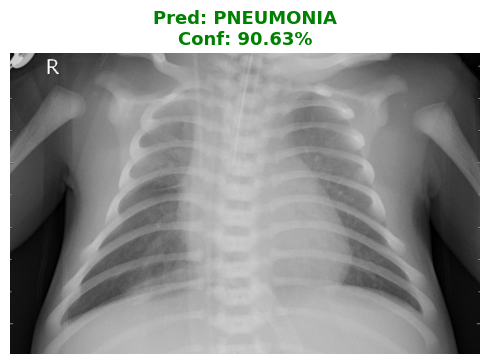


📌 Actual Class: TURBERCULOSIS
🔬 Image       : /kaggle/input/datasets/jtiptj/chest-xray-pneumoniacovid19tuberculosis/test/TURBERCULOSIS/Tuberculosis-680.png
   Predicted   : TURBERCULOSIS  (TTA=True)
   Confidence  : 89.44%

📊 All probabilities:
   COVID19        : 2.57%
   NORMAL         : 3.74%
   PNEUMONIA      : 4.25%
   TURBERCULOSIS  : 89.44% ← predicted


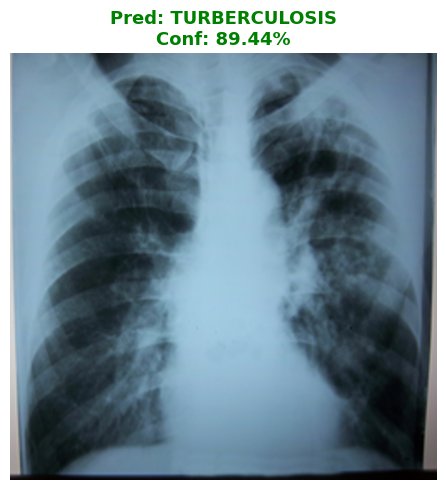

In [ ]:
# ── Test on one random image per class ──────────────────────
print("🔬 Running predictions on random test images …\n")
for cls in class_labels:
    cls_dir  = os.path.join(TEST_DIR, cls)
    files    = [f for f in os.listdir(cls_dir)
                if f.lower().endswith(('.jpg','.jpeg','.png'))]
    img_path = os.path.join(cls_dir, random.choice(files))
    print(f"{'='*55}")
    print(f"📌 Actual Class: {cls}")
    predict_xray(img_path, loaded_model, tta=True)
    print()


### 4.5 Prediction Grid (2×4)

A visual grid showing 2 predictions per class — green title = correct, red title = incorrect.

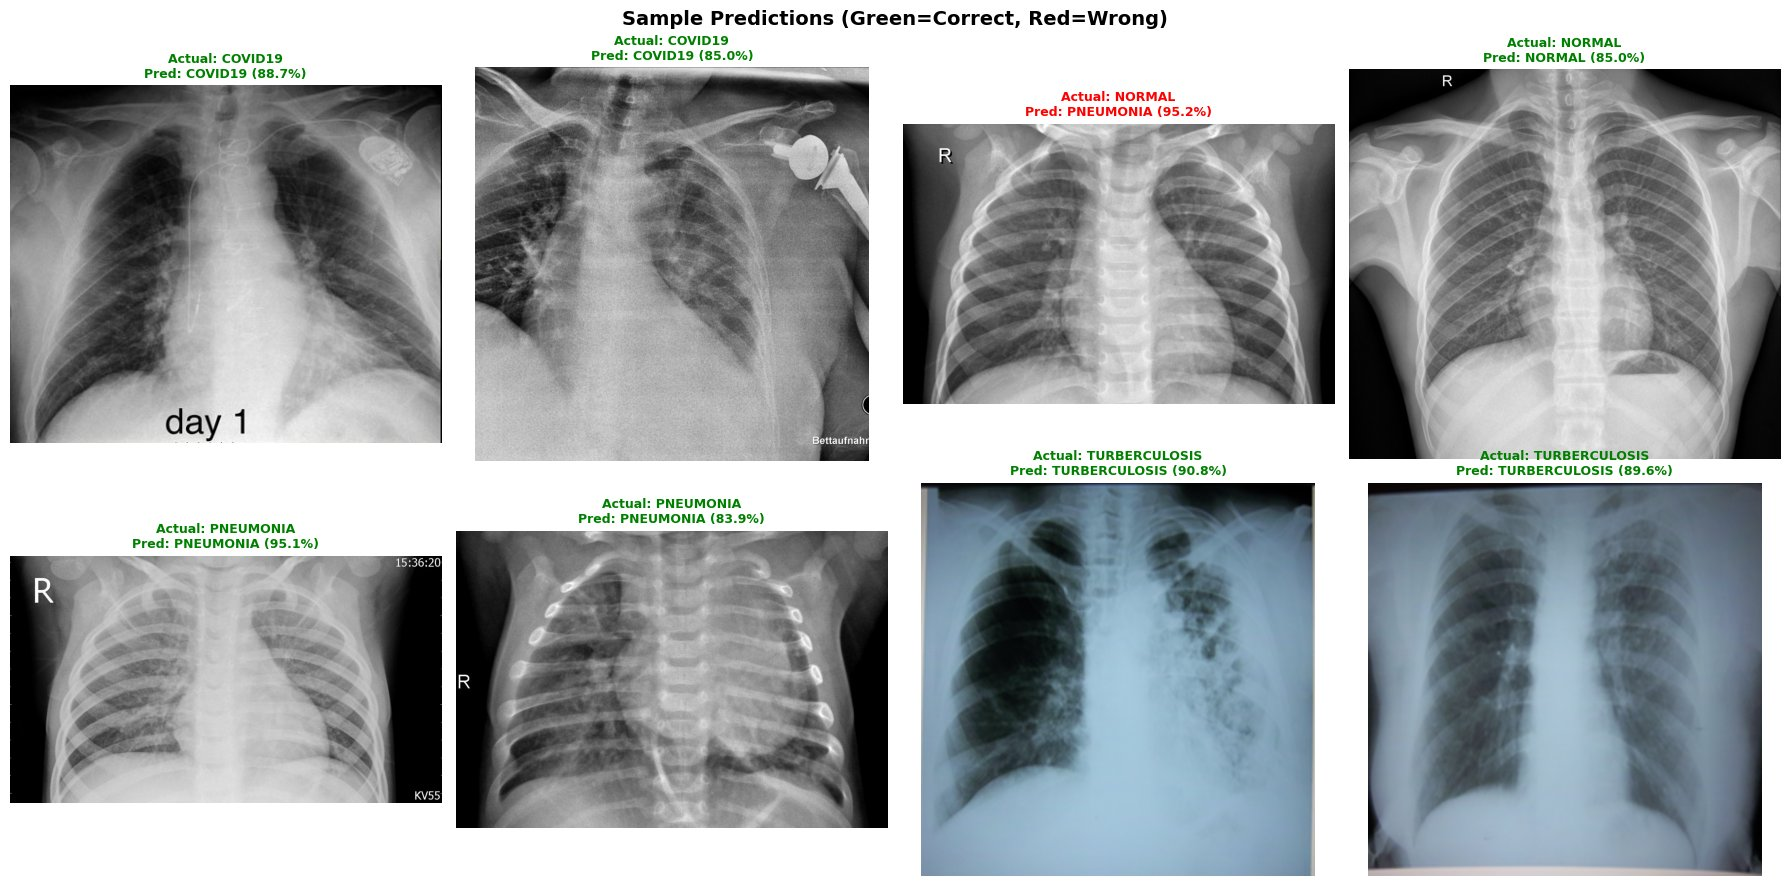

✅ Prediction grid saved


In [ ]:
# ── 2×4 prediction grid ─────────────────────────────────────
idx_to_cls_local = {v: k for k, v in train_generator.class_indices.items()}
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes      = axes.flatten()
plot_idx  = 0

for cls in class_labels:
    cls_dir = os.path.join(TEST_DIR, cls)
    files   = [f for f in os.listdir(cls_dir)
               if f.lower().endswith(('.jpg','.jpeg','.png'))]
    for fname in random.sample(files, min(2, len(files))):
        img_path = os.path.join(cls_dir, fname)
        base_img = Image.open(img_path).convert('RGB')
        arr      = np.array(base_img.resize((224, 224)), dtype=np.uint8)
        x        = np.expand_dims(clahe_preprocess(arr), axis=0)
        preds    = loaded_model.predict(x, verbose=0)[0]
        p_idx    = np.argmax(preds)
        p_cls    = idx_to_cls_local[p_idx]
        conf     = preds[p_idx] * 100

        axes[plot_idx].imshow(base_img, cmap='gray')
        axes[plot_idx].axis('off')
        col = 'green' if p_cls == cls else 'red'
        axes[plot_idx].set_title(
            f"Actual: {cls}\nPred: {p_cls} ({conf:.1f}%)",
            fontsize=9, fontweight='bold', color=col)
        plot_idx += 1
        if plot_idx >= 8:
            break
    if plot_idx >= 8:
        break

plt.suptitle('Sample Predictions (Green=Correct, Red=Wrong)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('sample_predictions.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Prediction grid saved")


### 4.6 Download Model Files

In [ ]:
# ── Download model files ────────────────────────────────────
from google.colab import files
files.download('chest_xray_resnet50_advanced.h5')
files.download('class_indices.json')
print("✅ Files downloaded!")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Files downloaded!


## Task 5 — Summary & Reflection

### Final Results

| Metric | Validation | Test (Standard) |
|---|---|---|
| Accuracy | 97.89% | **92.35%** |
| Precision | 97.92% | 92.38% |
| Recall | 97.89% | 92.35% |
| F1-Score | 97.90% | 92.27% |

Per-class test F1: COVID-19 1.00 · Tuberculosis 1.00 · Pneumonia 0.93 · Normal 0.87.

### Phase-by-Phase Best Validation Accuracy

| Phase | Best Val Accuracy |
|---|---|
| Phase 1 (head only) | 96.31% |
| Phase 2 (top 55 layers) | 97.78% |
| Phase 3 (all layers) | **98.42%** |

### Key Design Decisions & Their Impact

| Decision | Impact |
|---|---|
| CLAHE preprocessing | Enhances local X-ray contrast; improves feature visibility for ResNet50 |
| 15% val split (948 images) | Replaced noisy 38-image val; smooth, reliable training curves |
| No horizontal flip | Preserves the left-sided heart position, a diagnostically important feature |
| Unfreeze 55 layers (not 30) | Allows adaptation of mid-level features to X-ray domain |
| Class weights | Prevents bias toward majority class (Pneumonia) |
| Label smoothing 0.1 | Reduces over-confidence; improves generalisation |
| 3-phase training | Progressive unfreezing prevents catastrophic forgetting |

### Challenges & Observations

1. **NORMAL vs PNEUMONIA confusion** — NORMAL recall on test is 0.83, so about 17% of normal X-rays are misclassified, mostly as Pneumonia. Early-stage pneumonia and normal lungs can appear visually similar. Further improvement would require more NORMAL training data, stronger augmentation for that class, or a tuned decision threshold.

2. **TTA hurt performance** — Even without horizontal flips, TTA (84.70%) scored lower than standard evaluation (92.35%): NORMAL recall fell from 0.83 to 0.50 because small geometric changes push borderline NORMAL images toward PNEUMONIA. Standard evaluation is reported as the final score.

3. **Val–Test gap (98.42% → 92.35%)** — The validation images come from the same training folder (and so share its sources and acquisition conditions), while the test folder is a separate held-out set whose class mix also differs (for example 30% NORMAL in test vs 21% in the training folder). Some images from the same patient or source may also appear in both training and validation subsets. The gap shows that the held-out test score, not validation, is the realistic estimate of performance.

4. **Validation augmentation** — Because the validation subset uses the augmenting training generator, validation metrics are slightly noisy; a non-augmenting validation generator is a simple fix for future runs.

---

[← Evaluation & Test-Time Augmentation](04_evaluation_and_tta.ipynb) · **End of the project.** [Back to the start →](01_dataset_exploration.ipynb)